# Método de energía para la ecuación de onda

Sea $u_{tt}-c^2\Delta u=0$ en un dominio $\Omega$. La energía

$$
E(t)=\frac12\int_\Omega \bigl(u_t^2+c^2|\nabla u|^2\bigr)\,dx
$$

satisface

$$
\frac{dE}{dt}=c^2\int_{\partial\Omega}u_t\,\partial_\nu u\,dS.
$$

Por tanto, $E$ se conserva con Dirichlet homogénea ($u_t=0$ en la frontera), Neumann homogénea ($\partial_\nu u=0$) o condiciones periódicas. La misma identidad aplicada a la diferencia de dos soluciones prueba unicidad. En regiones troncocónicas, el balance local muestra velocidad finita de propagación.

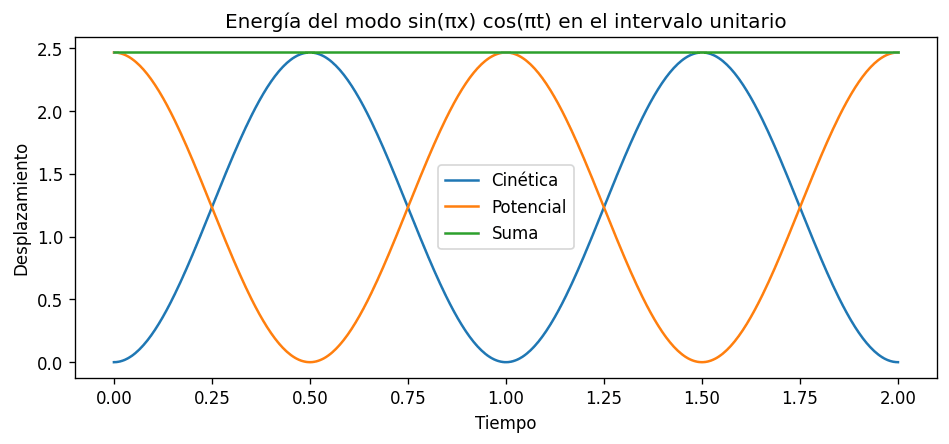

In [1]:
import numpy as np
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8,3.8))
ax.set(xlabel="Posición",ylabel="Desplazamiento")
t=np.linspace(0,2,400)
cinetica=np.pi**2*np.sin(np.pi*t)**2/4
potencial=np.pi**2*np.cos(np.pi*t)**2/4
for y, label in [(cinetica,"Cinética"),(potencial,"Potencial"),(cinetica+potencial,"Suma")]:
    ax.plot(t,y,label=label)
ax.set_title("Energía del modo sin(πx) cos(πt) en el intervalo unitario")
ax.set_xlabel("Tiempo")
ax.legend()
fig.tight_layout()
plt.show()

In [ ]:
from manim import *

class BalanceDeEnergia(Scene):
    def construct(self):
        title = Text("Energía = cinética + potencial", font_size=36).to_edge(UP)
        box = RoundedRectangle(width=8, height=3.6, color=BLUE)
        kinetic = Rectangle(width=2.8, height=1.2, fill_opacity=0.7, color=YELLOW).move_to(LEFT*1.8)
        potential = Rectangle(width=2.8, height=1.2, fill_opacity=0.7, color=GREEN).move_to(RIGHT*1.8)
        kl = Text("u_t²", font_size=30).move_to(kinetic)
        pl = Text("c²|∇u|²", font_size=30).move_to(potential)
        caption = Text("recinto sin flujo por la frontera", font_size=27).next_to(box, DOWN)
        self.play(FadeIn(title), Create(box), FadeIn(kinetic, kl, potential, pl), FadeIn(caption))
        self.wait(4)
        for _ in range(2):
            self.play(
                kinetic.animate.set_width(4.2),
                potential.animate.set_width(1.4),
                run_time=2
            )
            self.play(
                kinetic.animate.set_width(1.4),
                potential.animate.set_width(4.2),
                run_time=2
            )
        total = Text("la distribución cambia; la suma permanece constante", font_size=27).next_to(box, DOWN)
        self.play(Transform(caption, total))
        self.wait(3)

from IPython.display import Video, display

with tempconfig({"pixel_width": 2560, "pixel_height": 1440, "frame_rate": 120,
                 "write_to_movie": True, "format": "mp4", "preview": False}):
    escena = BalanceDeEnergia()
    escena.render()
    pelicula = escena.renderer.file_writer.movie_file_path
display(Video(str(pelicula), embed=True))


## Ejercicios esenciales

1. Derive la identidad de energía en un intervalo $[0,L]$ e indique exactamente dónde se usan las condiciones de frontera.
2. Sean $u$ y $v$ soluciones con los mismos datos iniciales y de frontera. Aplique la energía a $w=u-v$ para demostrar unicidad.

**Chequeo físico.** El término de frontera es potencia: si no se anula, la energía interior no tiene por qué conservarse.